# 08 · Fingerprints of fractionalisation: dynamics and thermodynamics

**What you will learn**
1. Dynamical structure factor $S(q,\omega)$ by continued-fraction Lanczos. Compare the sharp magnons of an ordered magnet with the two-spinon continuum of the Heisenberg chain.
2. The mean-field spinon continuum of the kagome Dirac spin liquid.
3. Specific heat, entropy and susceptibility by FTLM, which is parallel over random vectors and $S^z$ sectors.

In [1]:
import numpy as np, matplotlib.pyplot as plt, time
import qslab
from qslab import lattice, models, ED
from qslab.ed import ftlm_thermodynamics, thermodynamics_from_spectrum
from qslab.parton import SpinonAnsatz

## 1. S(q, ω) of the Heisenberg chain: the des Cloizeaux-Pearson continuum

17.9s


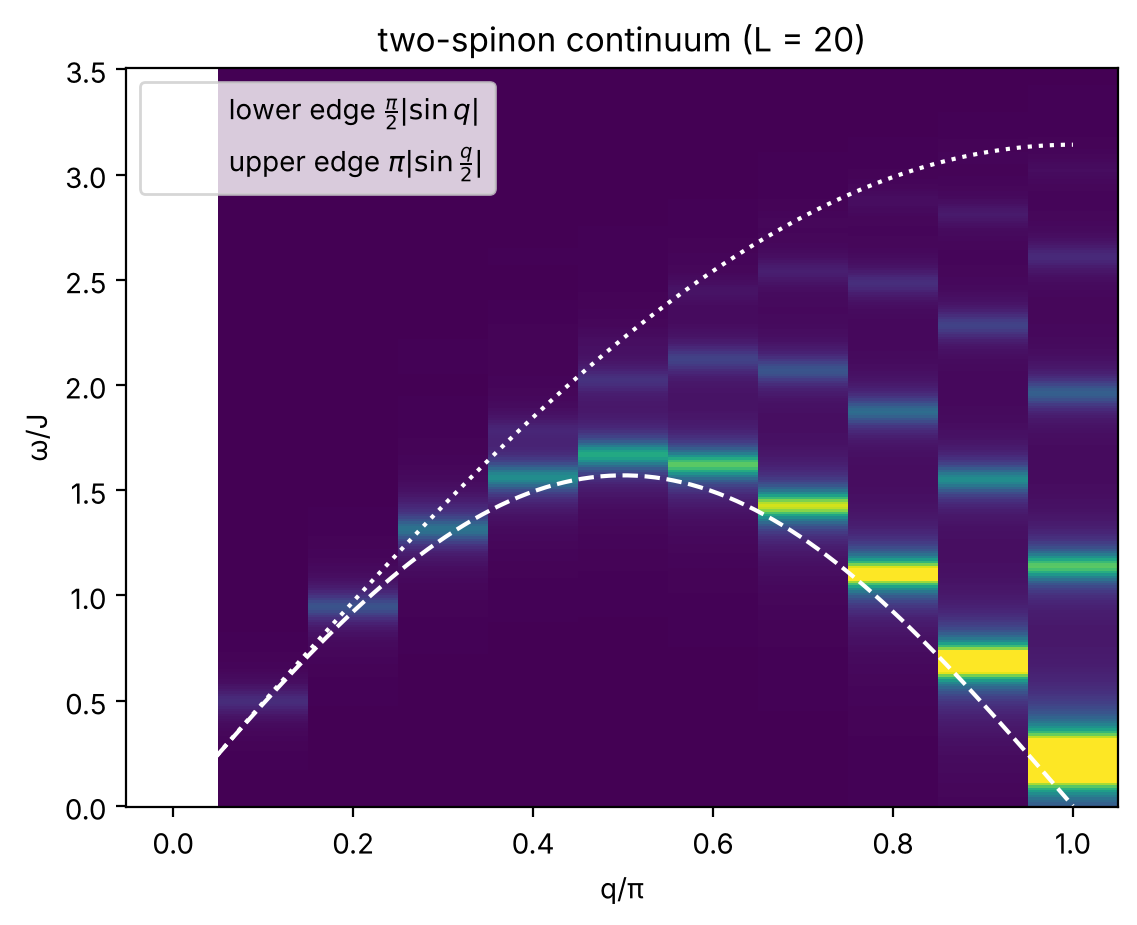

In [2]:
L = 20
latc, H = models.xxz_chain(L)
ed = ED(H, L); E0, psi0 = ed.ground_state()
qs = np.array([[2 * np.pi * m / L, 0] for m in range(1, L // 2 + 1)])
om = np.linspace(0, 3.5, 300)
t = time.time(); Sqw = ed.sq_omega(psi0, E0, latc.positions, qs, om, component="z", eta=0.06); print(f"{time.time()-t:.1f}s")
plt.pcolormesh(qs[:, 0] / np.pi, om, Sqw.T, shading="nearest", vmax=np.percentile(Sqw, 99))
k = np.linspace(0, np.pi, 100)
plt.plot(k / np.pi, np.pi / 2 * np.abs(np.sin(k)), "w--", label=r"lower edge $\frac{\pi}{2}|\sin q|$")
plt.plot(k / np.pi, np.pi * np.abs(np.sin(k / 2)), "w:", label=r"upper edge $\pi|\sin\frac{q}{2}|$")
plt.xlabel("q/π"); plt.ylabel("ω/J"); plt.legend(loc="upper left"); plt.title("two-spinon continuum (L = 20)"); plt.show()

## 2. Kagome Dirac spin liquid: mean-field spinon continuum

3.6s


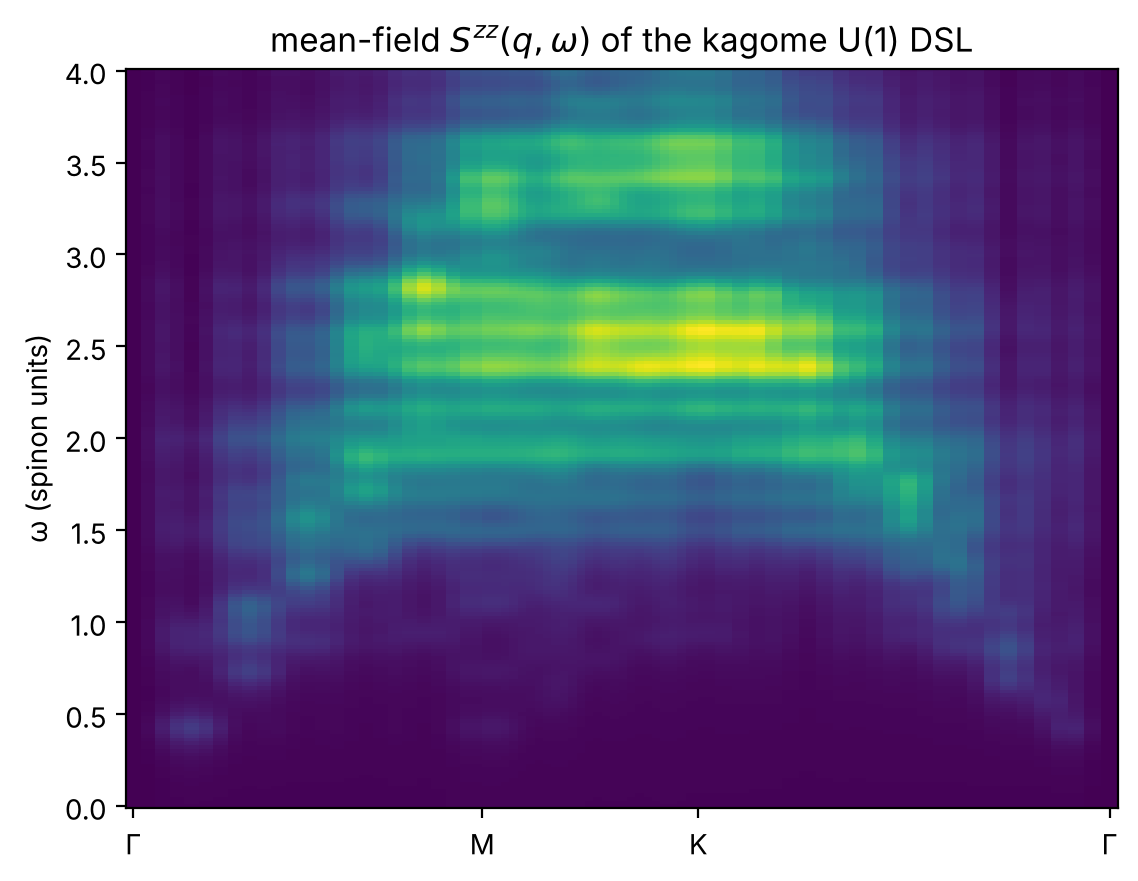

In [3]:
lat = lattice.kagome(12, 12)
ans = SpinonAnsatz.from_flux(lat, {"up": 0, "down": 0, "hexagon": np.pi})
lat1 = lattice.kagome(1, 1)
ks, dist, ticks = lat1.kpath(["G", "M", "K", "G"], n=24)
om = np.linspace(0, 4, 200)
t = time.time(); S = ans.dynamical_structure_factor(ks, om, eta=0.08); print(f"{time.time()-t:.1f}s")
plt.pcolormesh(dist, om, S.T, shading="nearest"); plt.xticks(ticks, ["Γ", "M", "K", "Γ"]); plt.ylabel("ω (spinon units)")
plt.title("mean-field $S^{zz}(q,ω)$ of the kagome U(1) DSL"); plt.show()

## 3. Thermodynamics with FTLM
FTLM is checked against full diagonalisation on 12 sites and then run on the 18-site kagome cluster.
Random vectors and $S^z$ sectors run in parallel (threads, or MPI ranks under `mpirun`).

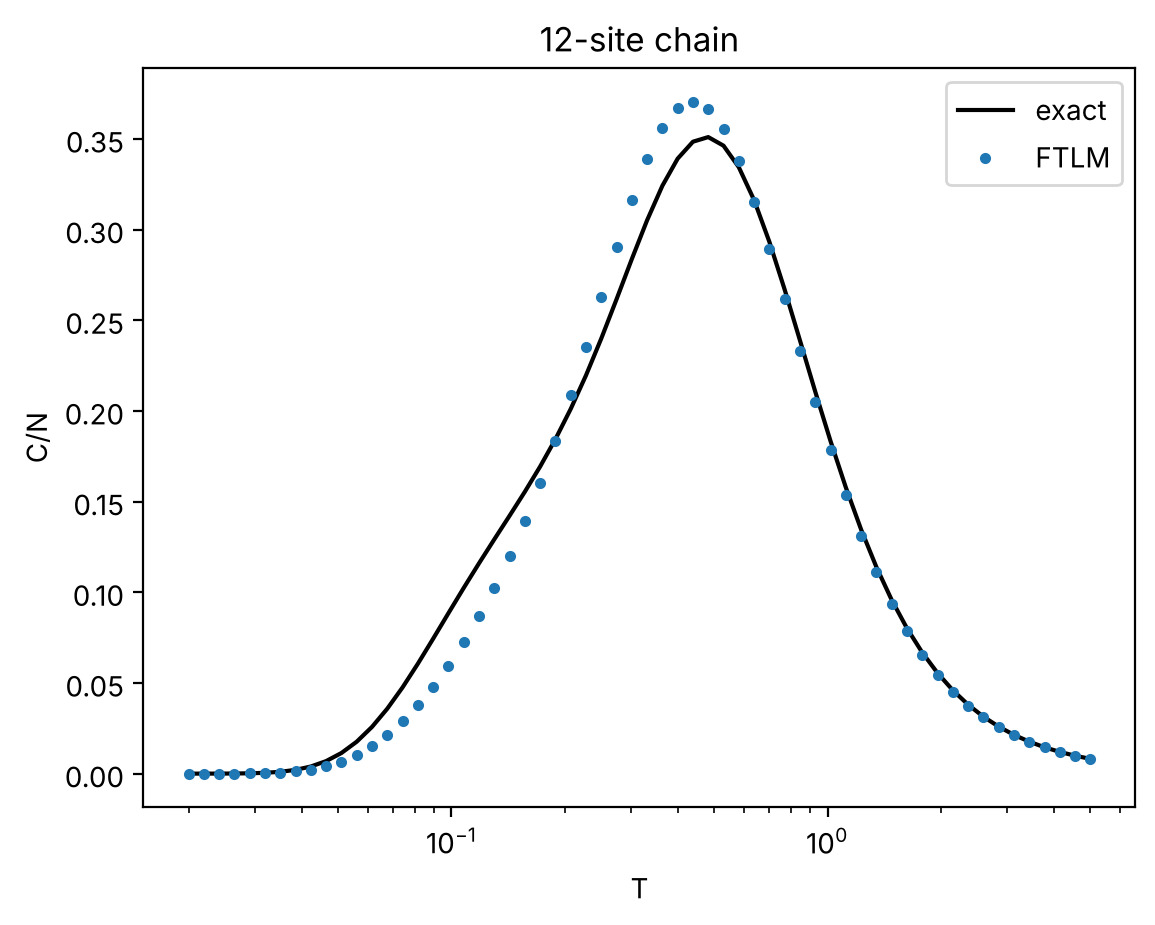

In [4]:
T = np.geomspace(0.02, 5, 60)
latc, Hc = models.xxz_chain(12)
ex = thermodynamics_from_spectrum(np.linalg.eigvalsh(Hc.to_matrix(12).real), T, 12)
ft = ftlm_thermodynamics(Hc, 12, T, R=30, M=100)
plt.semilogx(T, ex["C"], "k-", label="exact"); plt.semilogx(T, ft["C"], "o", ms=3, label="FTLM")
plt.xlabel("T"); plt.ylabel("C/N"); plt.legend(); plt.title("12-site chain"); plt.show()

18-site kagome FTLM: 8s


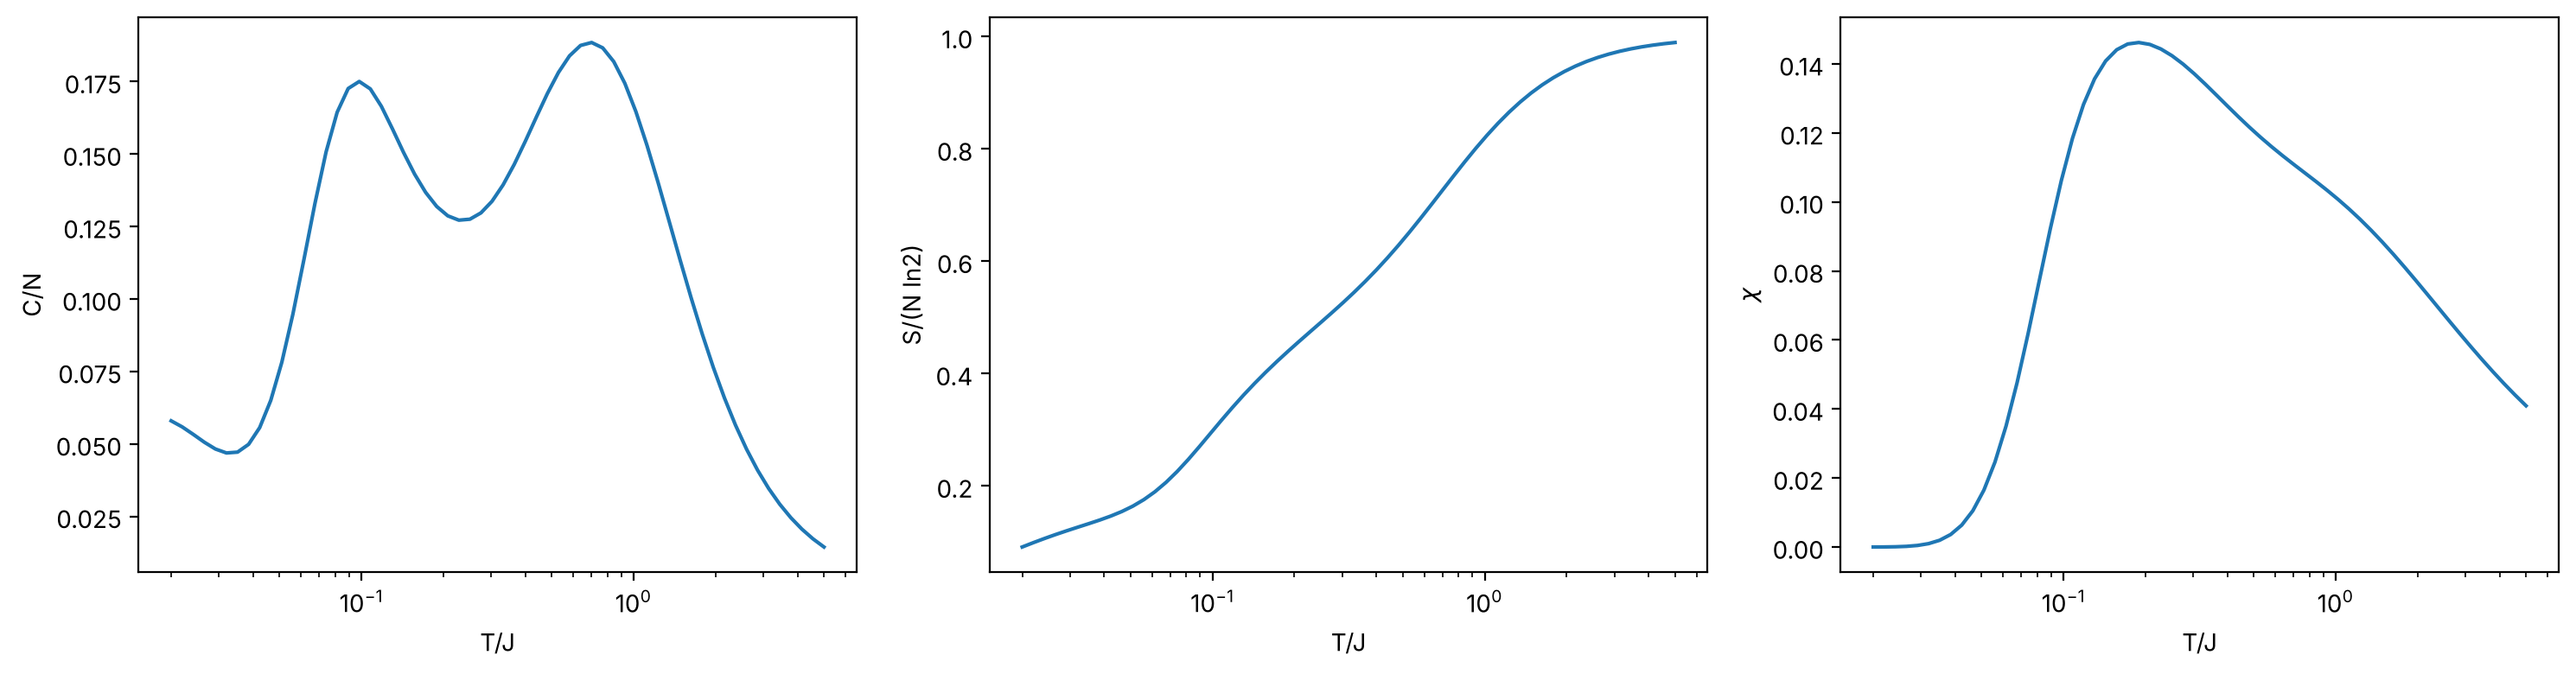

In [5]:
lat = lattice.kagome(2, 3)
t = time.time()
th = ftlm_thermodynamics(models.kagome_heisenberg(lat), lat.N, T, R=10, M=80)
print(f"18-site kagome FTLM: {time.time()-t:.0f}s")
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].semilogx(T, th["C"]); ax[0].set_ylabel("C/N")
ax[1].semilogx(T, th["S"] / np.log(2)); ax[1].set_ylabel("S/(N ln2)")
ax[2].semilogx(T, th["chi"]); ax[2].set_ylabel(r"$\chi$")
for a in ax: a.set_xlabel("T/J")
plt.tight_layout(); plt.show()

A low-temperature shoulder in C(T) below the main peak, together with a large residual entropy, is a classic kagome signature: there are many low-lying singlets.

## Quiz

In [6]:
from qslab import quiz
quiz.show("methods")

=== Methods and diagnostics for spin liquids ===
ED, DMRG, partons/VMC, NQS, thermodynamics, parallel computing

Q1. [mcq] Why can't ARPACK reliably count a 4-fold topological degeneracy with a tiny Krylov space?
    (a) Lanczos generates a single vector per degenerate eigenspace from one start vector; restarts or a large Krylov space are needed
    (b) It is complex
    (c) It always can
    (d) Because of round-off

Q2. [mcq] Which quantity distinguishes a gapped Z2 spin liquid from a trivial paramagnet?
    (a) topological entanglement entropy gamma = ln 2
    (b) zero magnetisation
    (c) <S_i.S_j> < 0
    (d) finite gap

Q3. [mcq] A smoking gun for fractionalisation in neutron scattering is
    (a) a spin gap
    (b) a broad continuum in S(q, w) instead of sharp magnons
    (c) a Bragg peak
    (d) a Curie law

Q4. [mcq] The QMC sign problem prevents
    (a) Majorana MC for Kitaev
    (b) unbiased QMC for frustrated Heisenberg models
    (c) ED
    (d) DMRG

Q5. [mcq] In qslab FT